In [171]:
import pandas as pd
from sqlalchemy import create_engine
import time
import requests
import pandas as pd
import numpy as np
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL



DB_CONFIG = {
    "host": "aws-0-eu-west-1.pooler.supabase.com",
    "port": 6543,
    "database": "postgres",
    "user": "postgres.palaoxigjbvbrgdnbstd",
    "password": "@ghZ2XjxsdL_*m*"
}



url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_CONFIG["user"],
    password=DB_CONFIG["password"],
    host=DB_CONFIG["host"],
    port=DB_CONFIG["port"],
    database=DB_CONFIG["database"]
)

engine = create_engine(url)

In [172]:
import pandas as pd


#demo istat
query_demo = """
select * from storica_demo
"""


query_anagrafica_comuni = """
select * from anagrafica_comuni
"""
query_centri = """
select * from accessibilita_centri_urbani"""

centri_urbani = pd.read_sql(query_centri, engine)

demo = pd.read_sql(query_demo, engine)

anag = pd.read_sql(query_anagrafica_comuni, engine)



In [173]:
anag.columns

Index(['codice_regione',
       'Codice dell'Unità territoriale sovracomunale \n(valida a fini s',
       'codice_provincia', 'Progressivo del Comune (2)', 'codice_comune',
       'Denominazione (Italiana e straniera)', 'Denominazione in italiano',
       'Denominazione altra lingua', 'Codice Ripartizione Geografica',
       'Ripartizione geografica', 'Denominazione Regione',
       'Denominazione_province',
       'Tipologia di Unità territoriale sovracomunale ',
       'Flag Comune capoluogo di Provincia/Città metropolitana/libero ',
       'Sigla automobilistica', 'Codice Comune formato numerico',
       'Codice Comune numerico con 107 Province (dal 2017 al 2025)',
       'Codice Comune numerico con 110 Province (dal 2010 al 2016)',
       'Codice Comune numerico con 107 Province (dal 2006 al 2009)',
       'Codice Comune numerico con 103 Province (dal 1995 al 2005)',
       'Codice Catastale del Comune', 'Codice NUTS1 2021',
       'Codice NUTS2 2021 (3) ', 'Codice NUTS3 2021', 'Co

## dati OMI

In [174]:
prezzi1 = pd.read_csv('prezzi_medi_province_AREZZO_BENEVENTO_BRINDISI_CATANZARO_CUNEO_FROSINONE_LA SPEZIA_LODI.csv', sep=';')
prezzi2 = pd.read_csv('prezzi_medi_province_BELLUNO_SONDRIO.csv',sep=';')
prezzi3 = pd.read_csv('prezzi_medi_province_ANCONA_BARI_BOLZANO_CASERTA_CREMONA_FOGGIA_IMPERIA_LECCO_MASSA CARRARA_NOVARA_PAVIA_PISTOIA_R.csv',sep=';')

In [175]:
prezzi_omi = pd.concat([prezzi1, prezzi2], ignore_index=True)

In [176]:
prezzi_omi.head()

,Provincia,Comune,Prezzo_Vendita,File
0,FROSINONE,ARCE,705.58,OMI_FR_ARCE_20252
1,LODI,CAVENAGO D'ADDA,1036.67,OMI_LO_CAVENAGO_D'ADDA_20252
2,BRINDISI,TORRE SANTA SUSANNA,525.00,OMI_BR_TORRE_SANTA_SUSANNA_20252
3,CUNEO,ROCCHETTA BELBO,777.00,OMI_CN_ROCCHETTA_BELBO_20252
4,CUNEO,CARAMAGNA PIEMONTE,1123.33,OMI_CN_CARAMAGNA_PIEMONTE_20252


In [177]:
prezzi_omi["comune_norm"] = (
    prezzi_omi["Comune"]
    .str.upper()
    .str.strip()
)

In [178]:
prezzi_omi.drop("Comune", axis=1, inplace=True)

In [179]:
prezzi_omi.head()

,Provincia,Prezzo_Vendita,File,comune_norm
0,FROSINONE,705.58,OMI_FR_ARCE_20252,ARCE
1,LODI,1036.67,OMI_LO_CAVENAGO_D'ADDA_20252,CAVENAGO D'ADDA
2,BRINDISI,525.00,OMI_BR_TORRE_SANTA_SUSANNA_20252,TORRE SANTA SUSANNA
3,CUNEO,777.00,OMI_CN_ROCCHETTA_BELBO_20252,ROCCHETTA BELBO
4,CUNEO,1123.33,OMI_CN_CARAMAGNA_PIEMONTE_20252,CARAMAGNA PIEMONTE


## dati sul rischio idrogeologico

In [180]:
idrogeo = pd.read_csv('Indicatori_Intero_territorio_nazionale.csv', sep=',', na_values=[''], quotechar='"')

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_42856/2155932705.py:1: DtypeWarning: Columns (21,32,48,51,97,98,99,100,101,112,115,116,117,118,122,142,145,146,147,154,155,156,157,158,159,160,161,162,184,186,190,191,192,193,202,205,208,214,217,220,223,226,392,394,395,396) have mixed types. Specify dtype option on import or set low_memory=False.
  idrogeo = pd.read_csv('Indicatori_Intero_territorio_nazionale.csv', sep=',', na_values=[''], quotechar='"')


In [181]:
df_ID = idrogeo[[
    "DZCOM",
    "PROCOM",
    "POP_2018",
    "POP_2011",
    "VAR_PERC",
    "VECCH",
    "POP_ANZ",
    "DENSPOP",
    "PAI_POPAA_P",
    "PAI_POPP3_P4_P",
    "PAI_AREAAA_P",
    "PAI_AREAP3_P4_P",
    "COMUNE_MONTANO",
    "ZONA_ALT"
]].copy()

In [182]:
'''
    "DZCOM": "Nome del comune",
    "PROCOM": "Codice ISTAT del comune",
    "POP_2018": "Popolazione residente al 2018",
    "POP_2011": "Popolazione residente al 2011",
    "VAR_PERC": "Variazione percentuale della popolazione tra 2011 e 2018",
    "VECCH": "Indice di vecchiaia",
    "POP_ANZ": "Popolazione anziana residente",
    "DENSPOP": "Densità della popolazione (abitanti per km²)",
    "PAI_POPAA_P": "Percentuale della popolazione residente in aree a pericolosità idrogeologica",
    "PAI_POPP3_P4_P": "Percentuale della popolazione residente nelle aree a pericolosità elevata e molto elevata (P3 + P4)",
    "PAI_AREAAA_P": "Percentuale della superficie comunale classificata a rischio idrogeologico",
    "PAI_AREAP3_P4_P": "Percentuale della superficie comunale classificata a pericolosità elevata e molto elevata (P3 + P4)",
    "COMUNE_MONTANO": "Indicatore che identifica se il comune è classificato come montano",
    "ZONA_ALT": "Classe altimetrica del comune"
'''

'\n    "DZCOM": "Nome del comune",\n    "PROCOM": "Codice ISTAT del comune",\n    "POP_2018": "Popolazione residente al 2018",\n    "POP_2011": "Popolazione residente al 2011",\n    "VAR_PERC": "Variazione percentuale della popolazione tra 2011 e 2018",\n    "VECCH": "Indice di vecchiaia",\n    "POP_ANZ": "Popolazione anziana residente",\n    "DENSPOP": "Densità della popolazione (abitanti per km²)",\n    "PAI_POPAA_P": "Percentuale della popolazione residente in aree a pericolosità idrogeologica",\n    "PAI_POPP3_P4_P": "Percentuale della popolazione residente nelle aree a pericolosità elevata e molto elevata (P3 + P4)",\n    "PAI_AREAAA_P": "Percentuale della superficie comunale classificata a rischio idrogeologico",\n    "PAI_AREAP3_P4_P": "Percentuale della superficie comunale classificata a pericolosità elevata e molto elevata (P3 + P4)",\n    "COMUNE_MONTANO": "Indicatore che identifica se il comune è classificato come montano",\n    "ZONA_ALT": "Classe altimetrica del comune"\n'

In [183]:
df_ID.head()


,DZCOM,PROCOM,POP_2018,POP_2011,VAR_PERC,VECCH,POP_ANZ,DENSPOP,PAI_POPAA_P,PAI_POPP3_P4_P,PAI_AREAAA_P,PAI_AREAP3_P4_P,COMUNE_MONTANO,ZONA_ALT
0,Altino,69001,3104,2844,"9,142053445850914","132,72357723577235","6,701030927835052","202,4735166727548",0,29984,0,"581,302300512",1,3
1,Archi,69002,2136,2280,"-6,315789473684211","233,0739299610895","9,597378277153558","74,82974131890923",0,29984,0,"581,302300512",3,3
2,Ari,69003,1148,1161,"-1,119724375538329","306,55737704918033","9,843205574912892","100,77512574944916",0,29984,0,"581,302300512",1,4
3,Arielli,69004,1129,1142,"-1,138353765323993","250,3875968992248","9,21169176262179","96,35654481987555",0,29984,0,"581,302300512",1,4
4,Atessa,69005,10580,10767,"-1,736788334726479","168,4536082474227","7,381852551984877","95,33421038404009",0,29984,0,"581,302300512",2,4


In [184]:
df_ID["comune_norm"] = (
    df_ID["DZCOM"]
    .str.upper()
    .str.strip()
)

In [185]:
df_ID["comune_norm"] = (df_ID["comune_norm"].
                        str.replace(r"\(.*?\)", "", regex=True)
    .str.strip())

## dato su impianti dismessi

In [186]:
impianti_dismessi = pd.read_csv("impianti_dismessi.csv")

impianti_dismessi["comune_norm"] = (
    impianti_dismessi["comune"]
    .str.upper()
    .str.strip()
)

# casi tipo "Macugnaga (VCO)"
impianti_dismessi["comune_norm"] = (
    impianti_dismessi["comune_norm"]
    .str.replace(r"\(.*?\)", "", regex=True)
    .str.strip()
)

In [187]:
mapping = {
    "DESERTETTO, LOC. DI VALDIERI": "VALDIERI",
    "COLLE DEL SOMMEILLER - BARDONECCHIA": "BARDONECCHIA",
    "OGGEBIO": "OGGEBBIO",
    "MUCRONE": np.nan,
}

impianti_dismessi["comune_norm"] = (
    impianti_dismessi["comune_norm"]
    .replace(mapping)
)

In [188]:
impianti_count = (
    impianti_dismessi.groupby("comune_norm")
    .size()
    .reset_index(name="n_impianti_dismessi")
)

In [189]:
impianti_dismessi.head()

,Unnamed: 0,id,nome,regione,provincia,comune,quota,tipologia,anno_costruzione,anno_dismissione,comune_norm
0,0,1,BASILICATA 2024 2 2025 2 2026 3 Valle d’Aosta ...,Valle d'Aosta,AO,Challand-Saint Anselme,730 s.l.m. m,uno skilift,inizio anni ‘80,fine anni ‘90,CHALLAND-SAINT ANSELME
1,1,2,Impianto - Aymavilles,Valle d'Aosta,AO,Aymavilles,1400 m s.l.m - 1650 m s.l.m,uno skilift,anni ‘60,1973,AYMAVILLES
2,2,3,Impianto - Valtournenche,Valle d'Aosta,AO,Valtournenche,2400 m s.l.m. - 3.486 m s.l.m.,Funivia e annesso tunnel di cemento,1952,1993,VALTOURNENCHE
3,3,4,Impianto - La Magdaleine,Valle d'Aosta,AO,La Magdaleine,1660 m s.l.m. - 1820 m s.l.m.,uno skilift,1952,1993,LA MAGDALEINE
4,4,5,Impianto - Valtournenche,Valle d'Aosta,AO,Valtournenche,2900 m s.l.m circa,"quattro funivie, uno skilift",anni ‘60,inizio anni ’90,VALTOURNENCHE


In [190]:
print(anag.shape)

(7894, 42)


## dati anagrafici comuni

In [191]:
anag.columns

Index(['codice_regione',
       'Codice dell'Unità territoriale sovracomunale \n(valida a fini s',
       'codice_provincia', 'Progressivo del Comune (2)', 'codice_comune',
       'Denominazione (Italiana e straniera)', 'Denominazione in italiano',
       'Denominazione altra lingua', 'Codice Ripartizione Geografica',
       'Ripartizione geografica', 'Denominazione Regione',
       'Denominazione_province',
       'Tipologia di Unità territoriale sovracomunale ',
       'Flag Comune capoluogo di Provincia/Città metropolitana/libero ',
       'Sigla automobilistica', 'Codice Comune formato numerico',
       'Codice Comune numerico con 107 Province (dal 2017 al 2025)',
       'Codice Comune numerico con 110 Province (dal 2010 al 2016)',
       'Codice Comune numerico con 107 Province (dal 2006 al 2009)',
       'Codice Comune numerico con 103 Province (dal 1995 al 2005)',
       'Codice Catastale del Comune', 'Codice NUTS1 2021',
       'Codice NUTS2 2021 (3) ', 'Codice NUTS3 2021', 'Co

In [192]:
anag = anag[['Denominazione in italiano','0-299 (%)', '300-599 (%)', '600-899 (%)', '900-1199 (%)',
       '1200-1499 (%)', '1500-1999 (%)', '2000-2499 (%)', '>=2500 (%)',
       'comune_montano', 'Fascia_Prevalente', 'Classificazione_Finale','latitudine','longitudine']]

In [193]:


demo["comune_norm"] = (
    demo["comune_norm"]
    .str.upper()
    .str.strip()
)



anag["comune_norm"] = ( anag["Denominazione in italiano"]
    .str.upper()
    .str.strip())

centri_urbani["comune_norm"] = ( centri_urbani["comune"]
    .str.upper()
    .str.strip())

In [194]:
centri_urbani.head()

,regione,provincia,comune,popolazione,hub_15min_5000ab,hub_5000_vicino,hub_5000_pop,tempo_hub_5000,comune_norm
0,Lombardia,VA,Agra,381.0,1,Luino,14125.0,14.0,AGRA
1,Lombardia,VA,Albizzate,5184.0,8,Albizzate,5184.0,0.0,ALBIZZATE
2,Lombardia,VA,Angera,5329.0,2,Angera,5329.0,0.0,ANGERA
3,Lombardia,VA,Arcisate,9916.0,2,Arcisate,9916.0,0.0,ARCISATE
4,Lombardia,VA,Arsago Seprio,4735.0,11,Casorate Sempione,5596.0,5.0,ARSAGO SEPRIO


In [195]:
###per comuni con slash e doppia lingua
def clean_comune(x):
    return (
        x.upper()
         .split("/")[0]
         .strip()
    )

In [196]:
centri_urbani = centri_urbani.drop_duplicates(subset=["comune"])

In [197]:
centri_urbani = centri_urbani.dropna()

In [198]:
centri_urbani.drop('comune', axis=1, inplace=True)

## faccio merge dei vari dataset

In [199]:
df = (

        demo

    .merge(
        anag,
        on=["comune_norm"],
        how="inner"
    )
  .merge(centri_urbani, on=["comune_norm"], how="inner")
    .merge(df_ID, on=["comune_norm"], how="inner")
    .merge(prezzi_omi, on=["comune_norm"], how="inner")
)

In [200]:
df.columns

Index(['id_demo', 'comune', 'provincia_x', 'anno', 'm_anno_0', 'f_anno_0',
       't_anno_0', 'm_0_5_prima_infanzia', 'm_6_11_infanzia',
       'm_12_17_adolescenza', 'm_18_24_giovani_adulti',
       'm_25_34_adulti_giovani', 'm_35_44_adulti', 'm_45_54_adulti_maturi',
       'm_55_64_pre_senior', 'm_65_74_senior', 'm_75_e_oltre_anziani',
       'f_0_5_prima_infanzia', 'f_6_11_infanzia', 'f_12_17_adolescenza',
       'f_18_24_giovani_adulti', 'f_25_34_adulti_giovani', 'f_35_44_adulti',
       'f_45_54_adulti_maturi', 'f_55_64_pre_senior', 'f_65_74_senior',
       'f_75_e_oltre_anziani', 't_0_5_prima_infanzia', 't_6_11_infanzia',
       't_12_17_adolescenza', 't_18_24_giovani_adulti',
       't_25_34_adulti_giovani', 't_35_44_adulti', 't_45_54_adulti_maturi',
       't_55_64_pre_senior', 't_65_74_senior', 't_75_e_oltre_anziani',
       'totale_generale', 'delta_pct_acumulado', 'codice_comune',
       'codice_comune_normalizzato', 'comune_norm', 'id',
       'Denominazione in italiano', '

In [201]:
df.head()

,id_demo,comune,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,DENSPOP,PAI_POPAA_P,PAI_POPP3_P4_P,PAI_AREAAA_P,PAI_AREAP3_P4_P,COMUNE_MONTANO,ZONA_ALT,Provincia,Prezzo_Vendita,File
0,011001_2006,Ameglia,La Spezia,2006,23,16,39,105,77,108,...,"308,0396514622359",0,7654,0,"75,9458403144",1,4,LA SPEZIA,2065.0,OMI_SP_AMEGLIA_20252
1,011001_2005,Ameglia,La Spezia,2005,15,13,28,92,93,100,...,"308,0396514622359",0,7654,0,"75,9458403144",1,4,LA SPEZIA,2065.0,OMI_SP_AMEGLIA_20252
2,011001_2004,Ameglia,La Spezia,2004,16,17,33,104,88,92,...,"308,0396514622359",0,7654,0,"75,9458403144",1,4,LA SPEZIA,2065.0,OMI_SP_AMEGLIA_20252
3,011001_2003,Ameglia,La Spezia,2003,19,15,34,97,91,92,...,"308,0396514622359",0,7654,0,"75,9458403144",1,4,LA SPEZIA,2065.0,OMI_SP_AMEGLIA_20252
4,011001_2026,Ameglia,La Spezia,2026,11,13,24,55,79,96,...,"308,0396514622359",0,7654,0,"75,9458403144",1,4,LA SPEZIA,2065.0,OMI_SP_AMEGLIA_20252


In [202]:
print(df.shape)
print(df["comune_norm"].nunique())
print(df["anno"].min(), df["anno"].max())

(59455, 81)
718
1992 2026


In [203]:
df.duplicated(["comune_norm", "anno","provincia_x"]).sum() #check dei duplicati

np.int64(34375)

In [204]:
dup = df[df.duplicated(["comune_norm", "anno","provincia_x"], keep=False)]

dup.sort_values(["comune_norm", "anno","provincia_x"])

,id_demo,comune,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,DENSPOP,PAI_POPAA_P,PAI_POPP3_P4_P,PAI_AREAAA_P,PAI_AREAP3_P4_P,COMUNE_MONTANO,ZONA_ALT,Provincia,Prezzo_Vendita,File
2520,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20232
2521,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20192
2522,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20152
2523,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20182
2524,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20126,025067_2026,Voltago Agordino,Belluno,2026,1,0,1,9,11,18,...,"36,387341977102395",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,792.14,OMI_BELLUNO_VOLTAGO_AGORDINO_20232
20127,025067_2026,Voltago Agordino,Belluno,2026,1,0,1,9,11,18,...,"36,387341977102395",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,792.14,OMI_BELLUNO_VOLTAGO_AGORDINO_20202
20128,025067_2026,Voltago Agordino,Belluno,2026,1,0,1,9,11,18,...,"36,387341977102395",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,785.71,OMI_BELLUNO_VOLTAGO_AGORDINO_20162
20129,025067_2026,Voltago Agordino,Belluno,2026,1,0,1,9,11,18,...,"36,387341977102395",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,792.14,OMI_BELLUNO_VOLTAGO_AGORDINO_20172


In [205]:
#df.drop('latitudine', axis=1, inplace=True)

In [206]:
dup = df[df.duplicated(["comune_norm", "anno","provincia_x"], keep=False)]
dup.sort_values(["comune_norm", "anno","provincia_x"])

,id_demo,comune,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,DENSPOP,PAI_POPAA_P,PAI_POPP3_P4_P,PAI_AREAAA_P,PAI_AREAP3_P4_P,COMUNE_MONTANO,ZONA_ALT,Provincia,Prezzo_Vendita,File
2520,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20232
2521,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20192
2522,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20152
2523,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20182
2524,025001_1992,Agordo,Belluno,1992,15,19,34,124,113,148,...,"172,22063109658504",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,1121.88,OMI_BELLUNO_AGORDO_20222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20126,025067_2026,Voltago Agordino,Belluno,2026,1,0,1,9,11,18,...,"36,387341977102395",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,792.14,OMI_BELLUNO_VOLTAGO_AGORDINO_20232
20127,025067_2026,Voltago Agordino,Belluno,2026,1,0,1,9,11,18,...,"36,387341977102395",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,792.14,OMI_BELLUNO_VOLTAGO_AGORDINO_20202
20128,025067_2026,Voltago Agordino,Belluno,2026,1,0,1,9,11,18,...,"36,387341977102395",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,785.71,OMI_BELLUNO_VOLTAGO_AGORDINO_20162
20129,025067_2026,Voltago Agordino,Belluno,2026,1,0,1,9,11,18,...,"36,387341977102395",3350,2677,"226,441085944","71,6172825177",3,1,BELLUNO,792.14,OMI_BELLUNO_VOLTAGO_AGORDINO_20172


In [207]:
df = df.sort_values(["comune_norm", "anno"]) #ordino per comune/anno

In [208]:
#crescita annuale: calcola la variazione percentuale annuale rispetto all'anno precedente
df["growth_rate"] = (
    df.groupby("comune_norm")["totale_generale"]
    .pct_change()
)

In [209]:
MIN_POP_BASE = 50

pop1992 = (
    df[df["anno"] == 1992][["comune_norm", "totale_generale"]]
    .rename(columns={"totale_generale": "pop1992"})
)

df = df.merge(pop1992, on="comune_norm", how="left")

df["growth_since_1992"] = np.where(
    df["pop1992"] >= MIN_POP_BASE,
    (df["totale_generale"] - df["pop1992"]) / df["pop1992"],
    np.nan
)

In [210]:
pop1992

,comune_norm,pop1992
37375,ABBADIA CERRETO,280
26350,ACCEGLIO,237
34365,ACQUAFONDATA,367
34400,ACUTO,1832
2520,AGORDO,4350
...,...,...
20469,VOLTAGO AGORDINO,1021
20470,VOLTAGO AGORDINO,1021
34330,VOTTIGNASCO,563
26315,ZAGARISE,2030


In [211]:

#df = df[df['comune_montano']==1]

In [212]:
df.head()

,id_demo,comune,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,PAI_AREAAA_P,PAI_AREAP3_P4_P,COMUNE_MONTANO,ZONA_ALT,Provincia,Prezzo_Vendita,File,growth_rate,pop1992,growth_since_1992
0,098001_1992,Abbadia Cerreto,Lodi,1992,2,1,3,7,5,8,...,0,0,1,5,LODI,1030.0,OMI_LO_ABBADIA_CERRETO_20252,NaN,280.0,0.000000
1,098001_1993,Abbadia Cerreto,Lodi,1993,0,2,2,7,8,8,...,0,0,1,5,LODI,1030.0,OMI_LO_ABBADIA_CERRETO_20252,0.057143,280.0,0.057143
2,098001_1994,Abbadia Cerreto,Lodi,1994,0,0,0,5,7,8,...,0,0,1,5,LODI,1030.0,OMI_LO_ABBADIA_CERRETO_20252,-0.037162,280.0,0.017857
3,098001_1995,Abbadia Cerreto,Lodi,1995,1,3,4,5,9,8,...,0,0,1,5,LODI,1030.0,OMI_LO_ABBADIA_CERRETO_20252,0.052632,280.0,0.071429
4,098001_1996,Abbadia Cerreto,Lodi,1996,0,3,3,4,7,10,...,0,0,1,5,LODI,1030.0,OMI_LO_ABBADIA_CERRETO_20252,0.043333,280.0,0.117857


## qui metto la soglia di spopolamento (qui 5%)

In [213]:
df["spopolamento"] = (df["growth_since_1992"] < -0.05).astype(int)
##variabili demo
df["anziani"] = df["t_65_74_senior"] + df["t_75_e_oltre_anziani"]

df["giovani"] = df["t_18_24_giovani_adulti"] + df["t_25_34_adulti_giovani"]

df["bambini"] = (
        df["t_0_5_prima_infanzia"] +
        df["t_6_11_infanzia"] +
        df["t_12_17_adolescenza"]
)

df["share_anziani"] = df["anziani"] / df["totale_generale"]
df["share_giovani"] = df["giovani"] / df["totale_generale"]
#df["indice_vecchiaia"] = df["anziani"] / df["bambini"]

In [214]:
target = df[df["anno"] == 2025]

target

,id_demo,comune,provincia_x,anno,m_anno_0,f_anno_0,t_anno_0,m_0_5_prima_infanzia,m_6_11_infanzia,m_12_17_adolescenza,...,File,growth_rate,pop1992,growth_since_1992,spopolamento,anziani,giovani,bambini,share_anziani,share_giovani
33,098001_2025,Abbadia Cerreto,Lodi,2025,3,1,4,9,6,9,...,OMI_LO_ABBADIA_CERRETO_20252,0.007326,280.0,-0.017857,0,72,37,40,0.261818,0.134545
68,004001_2025,Acceglio,Cuneo,2025,1,0,1,7,1,1,...,OMI_CN_ACCEGLIO_20252,0.031447,237.0,-0.308017,1,53,21,22,0.323171,0.128049
103,060001_2025,Acquafondata,Frosinone,2025,0,0,0,2,2,2,...,OMI_FR_ACQUAFONDATA_20252,-0.034884,367.0,-0.321526,1,81,33,18,0.325301,0.132530
138,060002_2025,Acuto,Frosinone,2025,1,4,5,26,49,50,...,OMI_FR_ACUTO_20252,-0.002197,1832.0,-0.008188,0,488,278,239,0.268575,0.152999
4133,025001_2025,Agordo,Belluno,2025,11,16,27,78,80,81,...,OMI_BELLUNO_AGORDO_20232,-0.007164,4350.0,-0.076092,1,1144,733,500,0.284648,0.182384
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363258,025067_2025,Voltago Agordino,Belluno,2025,0,2,2,8,11,18,...,OMI_BELLUNO_VOLTAGO_AGORDINO_20212,0.000000,1021.0,-0.225269,1,249,131,79,0.314791,0.165613
363259,025067_2025,Voltago Agordino,Belluno,2025,0,2,2,8,11,18,...,OMI_BELLUNO_VOLTAGO_AGORDINO_20212,0.000000,1021.0,-0.225269,1,249,131,79,0.314791,0.165613
363393,004250_2025,Vottignasco,Cuneo,2025,0,1,1,4,12,10,...,OMI_CN_VOTTIGNASCO_20252,0.020243,563.0,-0.104796,1,139,98,59,0.275794,0.194444
363428,079157_2025,Zagarise,Catanzaro,2025,0,2,2,16,28,31,...,OMI_CZ_ZAGARISE_20252,-0.020086,2030.0,-0.327094,1,410,221,169,0.300146,0.161786


In [215]:
analysis_df = target.copy()

In [216]:
analysis_df.columns

Index(['id_demo', 'comune', 'provincia_x', 'anno', 'm_anno_0', 'f_anno_0',
       't_anno_0', 'm_0_5_prima_infanzia', 'm_6_11_infanzia',
       'm_12_17_adolescenza', 'm_18_24_giovani_adulti',
       'm_25_34_adulti_giovani', 'm_35_44_adulti', 'm_45_54_adulti_maturi',
       'm_55_64_pre_senior', 'm_65_74_senior', 'm_75_e_oltre_anziani',
       'f_0_5_prima_infanzia', 'f_6_11_infanzia', 'f_12_17_adolescenza',
       'f_18_24_giovani_adulti', 'f_25_34_adulti_giovani', 'f_35_44_adulti',
       'f_45_54_adulti_maturi', 'f_55_64_pre_senior', 'f_65_74_senior',
       'f_75_e_oltre_anziani', 't_0_5_prima_infanzia', 't_6_11_infanzia',
       't_12_17_adolescenza', 't_18_24_giovani_adulti',
       't_25_34_adulti_giovani', 't_35_44_adulti', 't_45_54_adulti_maturi',
       't_55_64_pre_senior', 't_65_74_senior', 't_75_e_oltre_anziani',
       'totale_generale', 'delta_pct_acumulado', 'codice_comune',
       'codice_comune_normalizzato', 'comune_norm', 'id',
       'Denominazione in italiano', '

# clustering

In [217]:
cluster_features = [
    "share_anziani",
    "share_giovani",
    "popolazione",
    "0-299 (%)",
    "600-899 (%)",
    ">=2500 (%)",
    "tempo_hub_5000",
    "hub_15min_5000ab",
    "hub_5000_pop",
    "PAI_POPP3_P4_P",
    "DENSPOP",
    'Prezzo_Vendita'

]

In [218]:
import seaborn as sns
import matplotlib.pyplot as plt

In [219]:
analysis_df[cluster_features].dtypes

share_anziani       float64
share_giovani       float64
popolazione         float64
0-299 (%)           float64
600-899 (%)         float64
>=2500 (%)          float64
tempo_hub_5000      float64
hub_15min_5000ab      int64
hub_5000_pop        float64
PAI_POPP3_P4_P        int64
DENSPOP              object
Prezzo_Vendita      float64
dtype: object

In [220]:
analysis_df[cluster_features].head()

,share_anziani,share_giovani,popolazione,0-299 (%),600-899 (%),>=2500 (%),tempo_hub_5000,hub_15min_5000ab,hub_5000_pop,PAI_POPP3_P4_P,DENSPOP,Prezzo_Vendita
33,0.261818,0.134545,275.0,100.000000,0.000000,0.000000,16.0,0,45357.0,0,"46,62267894881185",1030.00
68,0.323171,0.128049,164.0,0.000000,0.000000,32.065111,43.0,0,7024.0,8573,"1,0360991461091178",807.50
103,0.325301,0.132530,249.0,0.000000,42.844047,0.000000,27.0,0,5599.0,36320,"10,5452735846821",398.75
138,0.268575,0.152999,1817.0,0.014848,59.363307,0.000000,13.0,1,10195.0,36320,"141,01764391374087",330.83
4133,0.284648,0.182384,4019.0,0.000000,26.403491,2.726109,25.0,0,10129.0,2677,"172,22063109658504",1121.88


In [221]:
analysis_df["DENSPOP"] = (
    analysis_df["DENSPOP"]
    .str.replace(",", ".", regex=False)
    .astype(float)
)

In [222]:
clustering_df = (
    analysis_df[
        [
            "comune_norm",
            "Denominazione in italiano",
            "latitudine",
            "longitudine",
            *cluster_features
        ]
    ]
    .groupby(["comune_norm", "Denominazione in italiano"], as_index=False)
    .mean(numeric_only=True)
)

In [223]:
clustering_df.dtypes

comune_norm                   object
Denominazione in italiano     object
latitudine                   float64
longitudine                  float64
share_anziani                float64
share_giovani                float64
popolazione                  float64
0-299 (%)                    float64
600-899 (%)                  float64
>=2500 (%)                   float64
tempo_hub_5000               float64
hub_15min_5000ab             float64
hub_5000_pop                 float64
PAI_POPP3_P4_P               float64
DENSPOP                      float64
Prezzo_Vendita               float64
dtype: object

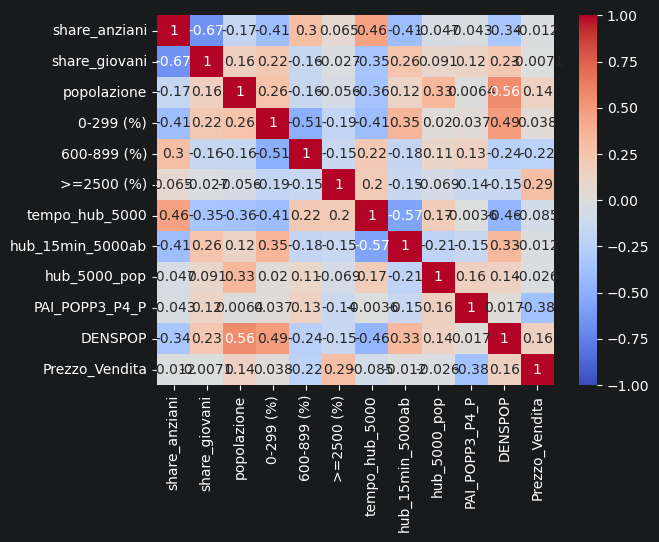

In [224]:
sns.heatmap(clustering_df[cluster_features].corr(method="pearson"), cmap="coolwarm", vmin=-1, vmax=1, annot=True)
plt.show()

In [225]:
from scipy.spatial.distance import pdist, cdist, squareform

In [226]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.stats import pearsonr, spearmanr

def get_sse(X, labels):
    sse = 0
    for l in np.unique(labels):
        c = np.mean(X[labels == l], axis=0)
        sse += np.sum(cdist(np.expand_dims(c, axis=0), X[labels == l]))
    return sse

def get_bss(X, labels):
    cluster_centers = list()
    for l in np.unique(labels):
        c = np.mean(X[labels == l], axis=0)
        cluster_centers.append(c)
    cluster_centers = np.array(cluster_centers)
    _, sizes = np.unique(labels, return_counts=True)
    m = np.mean(X, axis=0)
    bss = np.sum(sizes * cdist(np.expand_dims(m, axis=0), cluster_centers))
    return bss

def get_ideal_matrix(X, labels):
    P = np.ones((len(X), len(X)))
    for i in np.arange(len(X)):
        for j in np.arange(len(X)):
            if labels[i] == labels[j]:
                P[i, j] = 0.
    return P

def eval_clustering(X, D, labels):
   # corr = spearmanr(D.ravel(), get_ideal_matrix(X, labels).ravel())[0]
    sse = get_sse(X[labels != -1], labels[labels != -1])
    bss = get_bss(X[labels != -1], labels[labels != -1])
    silh = silhouette_score(X[labels != -1], labels[labels != -1])
    davis = davies_bouldin_score(X, labels)
    return (#corr,
            sse, bss, silh, davis)

### kmenas

In [227]:
X = clustering_df[cluster_features].copy()
X[:10]

,share_anziani,share_giovani,popolazione,0-299 (%),600-899 (%),>=2500 (%),tempo_hub_5000,hub_15min_5000ab,hub_5000_pop,PAI_POPP3_P4_P,DENSPOP,Prezzo_Vendita
0,0.261818,0.134545,275.0,100.000000,0.000000,0.000000,16.0,0.0,45357.0,0.0,46.622679,1030.000000
1,0.323171,0.128049,164.0,0.000000,0.000000,32.065111,43.0,0.0,7024.0,8573.0,1.036099,807.500000
2,0.325301,0.132530,249.0,0.000000,42.844047,0.000000,27.0,0.0,5599.0,36320.0,10.545274,398.750000
3,0.268575,0.152999,1817.0,0.014848,59.363307,0.000000,13.0,1.0,10195.0,36320.0,141.017644,330.830000
4,0.284648,0.182384,4019.0,0.000000,26.403491,2.726109,25.0,0.0,10129.0,2677.0,172.220631,1117.998182
5,0.209288,0.194260,8118.0,74.280725,7.129617,0.000000,0.0,1.0,8118.0,27807.0,563.185522,737.500000
6,0.406863,0.122549,204.0,0.000000,14.570060,7.527196,25.0,0.0,12517.0,8573.0,6.392580,747.500000
7,0.231848,0.177375,27518.0,27.827881,6.381451,0.000000,0.0,0.0,27518.0,36320.0,296.642289,965.950000
8,0.261884,0.177752,30987.0,79.167227,0.000000,0.000000,0.0,0.0,30987.0,8573.0,587.800590,1455.930000
9,0.350340,0.153061,294.0,0.000000,3.979659,0.000000,13.0,1.0,12358.0,6594.0,15.822284,902.606250


In [228]:
from sklearn.preprocessing import StandardScaler

In [229]:


scaler = StandardScaler()
X = scaler.fit_transform(X)

In [230]:
X[:10] #controllo il vettore riscalato

array([[-0.30693045, -1.21476779, -0.42213145,  1.74217879, -0.75466578,
        -0.22684432,  0.04255168, -0.83303397,  1.66365083, -1.21460835,
        -0.51178636,  0.21399859],
       [ 0.88796817, -1.47640585, -0.43430677, -0.83264194, -0.75466578,
         5.21944122,  2.17961604, -0.83303397, -0.51781962, -0.46273773,
        -0.78402896, -0.20788454],
       [ 0.92946114, -1.29593056, -0.42498333, -0.83264194,  1.31333073,
        -0.22684432,  0.91320753, -0.83303397, -0.59891412,  1.97073411,
        -0.72724027, -0.98291704],
       [-0.17534337, -0.47157711, -0.25299319, -0.83225962,  2.11068241,
        -0.22684432, -0.19489992,  0.01057448, -0.33736302,  1.97073411,
         0.05193943, -1.11170042],
       [ 0.13770022,  0.71180265, -0.01146113, -0.83264194,  0.51977796,
         0.23618748,  0.75490646, -0.83303397, -0.34111897, -0.97982966,
         0.23828336,  0.3808523 ],
       [-1.33000512,  1.19007994,  0.43814828,  1.07995358, -0.41053341,
        -0.22684432, -

In [231]:
from sklearn.cluster import KMeans

In [232]:
D = pdist(X, metric="euclidean") #uso la distanza classica euclidea per calcolare la matrice delle distanze

In [233]:
kmin = 2
kmax = 50
#valuto diversi modelli di K-Means Clustering variando il numero di cluster k, e calcolando varie metriche per capire quale valore di k sia migliore
krange = np.arange(kmin, kmax, 1)
D = pdist(X, metric="euclidean")

results = {
  #  "corr": list(),
    "sse": list(),
    "bss": list(),
    "silh": list(),
    "inertia": list(),
    "davis": list(),
}

for k in krange:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X)

    labels = kmeans.labels_

    ( #corr,
     sse, bss, silh, davis) = eval_clustering(X, squareform(D), labels)

   # results["corr"].append(corr)
    results["sse"].append(sse)
    results["bss"].append(bss)
    results["silh"].append(silh)
    results["inertia"].append(kmeans.inertia_)
    results["davis"].append(davis)

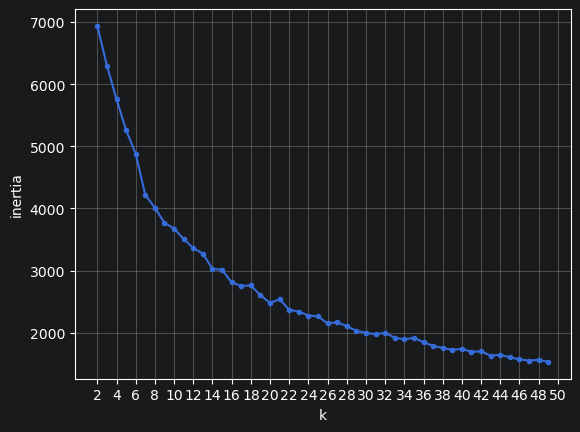

In [234]:
plt.plot(krange, results['inertia'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('inertia')
plt.xlabel('k')
plt.grid()
plt.show()
##Misura la somma delle distanze intra-cluster: prendere il gomito

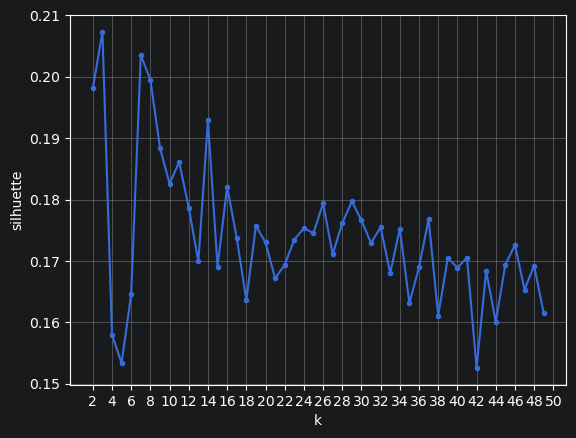

In [235]:
plt.plot(krange, results['silh'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('silhuette')
plt.xlabel('k')
plt.grid()
plt.show()
##Range: [-1, 1]
##Più è alto → meglio separati i cluster
##Interpretazione:
##~0.70 → cluster molto buoni
#~0.50 → discreti
#~0.25 → deboli
#<0 → clustering sbagliato

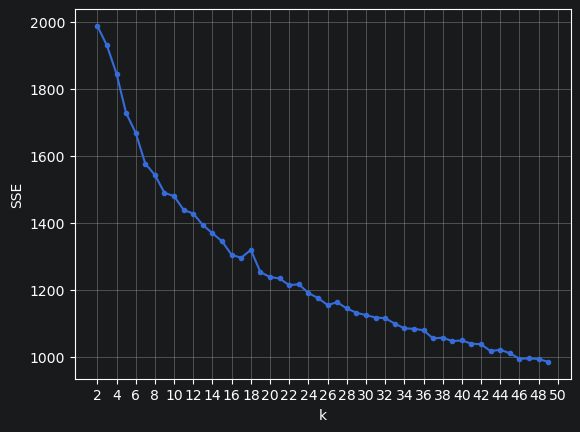

In [236]:
plt.plot(krange, results['sse'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('SSE')
plt.xlabel('k')
plt.grid()
plt.show()
# come inertia: prendere il gomiot

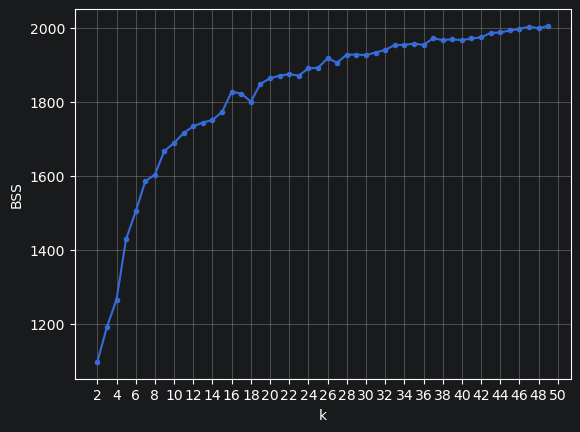

In [237]:
plt.plot(krange, results['bss'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('BSS')
plt.xlabel('k')
plt.grid()
plt.show()
###BSS (Between-Cluster Sum of Squares) — ↑ meglio
##Più alto = cluster più separati

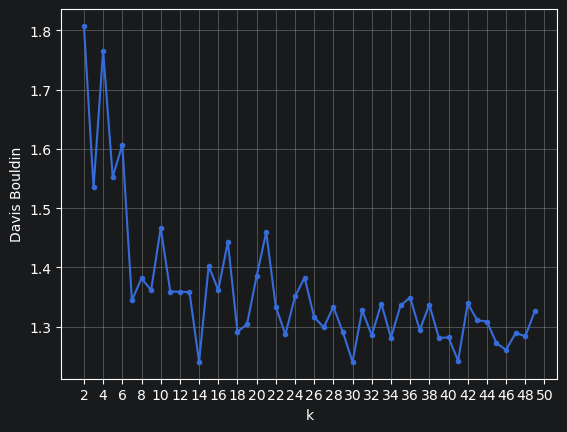

In [238]:
plt.plot(krange, results['davis'], marker='.')
plt.xticks(np.arange(2, kmax + 2, 2))
plt.ylabel('Davis Bouldin')
plt.xlabel('k')
plt.grid()
plt.show()
##Più basso = meglio
#Misura:
#compattezza cluster
#separazione tra cluster

### provo k = 7

In [239]:
k = 7
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20
)

kmeans.fit(X)

,n_clusters,7
,init,'k-means++'
,n_init,20
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [240]:
kmeans.fit(X)
clusteringCol = clustering_df.columns
clustering_df['kmeans_label'] = kmeans.labels_

In [241]:
cluster_features

['share_anziani',
 'share_giovani',
 'popolazione',
 '0-299 (%)',
 '600-899 (%)',
 '>=2500 (%)',
 'tempo_hub_5000',
 'hub_15min_5000ab',
 'hub_5000_pop',
 'PAI_POPP3_P4_P',
 'DENSPOP',
 'Prezzo_Vendita']

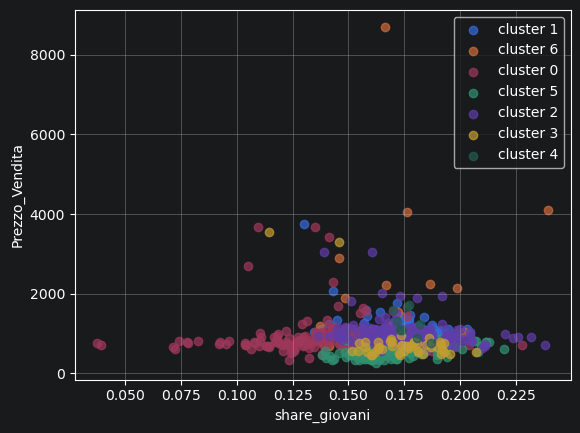

In [242]:
#mostro una 'sezione' di cluster
x = 'share_giovani'
y = 'Prezzo_Vendita'

for cluster in clustering_df['kmeans_label'].unique():
    df_analyzed = clustering_df[clustering_df['kmeans_label'] == cluster]
    plt.scatter(df_analyzed[x], df_analyzed[y], label="cluster %s" % cluster, alpha=0.7)

plt.xlabel(x)
#plt.xscale('log')
plt.ylabel(y)
plt.grid()
plt.legend()
plt.show()

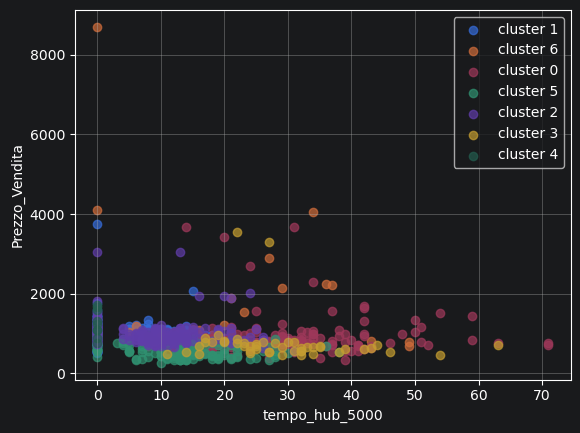

In [243]:
x = 'tempo_hub_5000'
y = 'Prezzo_Vendita'

for cluster in clustering_df['kmeans_label'].unique():
    df_analyzed = clustering_df[clustering_df['kmeans_label'] == cluster]
    plt.scatter(df_analyzed[x], df_analyzed[y], label="cluster %s" % cluster, alpha=0.7)

plt.xlabel(x)
#plt.xscale('log')
plt.ylabel(y)
plt.grid()
plt.legend()
plt.show()

In [244]:
cluster_summary = (
    clustering_df
    .groupby("kmeans_label")
    .mean(numeric_only=True)
    .round(2)
)

print(cluster_summary)

              latitudine  longitudine  share_anziani  share_giovani  \
kmeans_label                                                          
0             4918422.23    575670.71           0.34           0.14   
1             4876487.38    648299.20           0.24           0.17   
2             4979403.68    509535.43           0.26           0.18   
3             4487767.04   1043484.13           0.28           0.17   
4             4669580.32    846143.72           0.26           0.18   
5             4535919.69    967351.63           0.26           0.17   
6             5104315.50    547841.77           0.28           0.17   

              popolazione  0-299 (%)  600-899 (%)  >=2500 (%)  tempo_hub_5000  \
kmeans_label                                                                    
0                  762.55       6.94        25.05        1.14           27.12   
1                 7062.62      91.36         0.90        0.00            6.11   
2                 3318.31      10.69

# Plot

In [245]:
clustering_df.columns

Index(['comune_norm', 'Denominazione in italiano', 'latitudine', 'longitudine',
       'share_anziani', 'share_giovani', 'popolazione', '0-299 (%)',
       '600-899 (%)', '>=2500 (%)', 'tempo_hub_5000', 'hub_15min_5000ab',
       'hub_5000_pop', 'PAI_POPP3_P4_P', 'DENSPOP', 'Prezzo_Vendita',
       'kmeans_label'],
      dtype='object')

In [246]:
from pyproj import Transformer

In [247]:
transformer = Transformer.from_crs(
    "EPSG:25832",   # coordinate originali
    "EPSG:4326",    # lat/lon
    always_xy=True
)

In [248]:
lon, lat = transformer.transform(
    clustering_df["longitudine"].values,
    clustering_df["latitudine"].values
)

clustering_df["lon"] = lon
clustering_df["lat"] = lat

In [249]:
clustering_df[["lat","lon"]].head()

,lat,lon
0,45.313169,9.591732
1,44.487264,6.950564
2,41.550945,13.974978
3,41.792224,13.174989
4,46.302963,12.047544


In [250]:
#clustering_df.to_csv("clustering.csv", index=False)

In [251]:
import folium
from folium.plugins import MarkerCluster

In [252]:
# Centro della mappa
m = folium.Map(
    location=[42.5, 12.5],
    zoom_start=6,
    tiles="CartoDB positron"
)

In [253]:
colors = {
    0: "red",
    1: "blue",
    2: "green",
    3: "purple",
    4: "orange",
    5: "darkred",
    6: "cadetblue",

}

In [254]:
marker_cluster = MarkerCluster().add_to(m)

for _, row in clustering_df.iterrows():

    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        continue

    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=5,
        color=colors[row["kmeans_label"]],
        fill=True,
        fill_color=colors[row["kmeans_label"]],
        fill_opacity=0.8,
        popup=f"""
        <b>{row['comune_norm']}</b><br>
        Cluster: {row['kmeans_label']}<br>
        Popolazione: {row['popolazione']:.0f}<br>
        Prezzo medio: {row['Prezzo_Vendita']:.0f} €/m²
        """
    ).add_to(marker_cluster)

m

In [255]:
## opzione 2 per la map
m = folium.Map(
    location=[clustering_df["lat"].mean(), clustering_df["lon"].mean()],
    zoom_start=7
)

for _, row in clustering_df.iterrows():

    if pd.isna(row["lat"]) or pd.isna(row["lon"]):
        continue

    folium.Marker(
        location=[row["lat"], row["lon"]],
        icon=folium.Icon(
        color=colors[row["kmeans_label"]],
        icon="info-sign"
    ),
        popup=f"""
        <b>{row['comune_norm']}</b><br>
        Cluster: {row['kmeans_label']}<br>
        Popolazione: {row['popolazione']:.0f}<br>
        Prezzo medio: {row['Prezzo_Vendita']:.0f} €/m²
        """
    ).add_to(m)

m